In [1]:
import numpy as np
import pandas as pd

# 1. Load the dataset
df = pd.read_csv('../Telco-Customer-Churn.csv')

# 2. Inspect basic info and missing values
print('Dataset Shape:', df.shape)
print('\n--- Data Types & Non-Null Counts ---')
df.info()

# 3. Clean 'TotalCharges' (it's often stored as object due to white spaces)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Check how many nulls were introduced
print(
    '\nMissing values in TotalCharges:', df['TotalCharges'].isnull().sum()
)

# Drop rows where TotalCharges is missing (very few rows)
df.dropna(subset=['TotalCharges'], inplace=True)

# 4. Drop customerID as it has no predictive value
if 'customerID' in df.columns:
    df.drop(columns=['customerID'], inplace=True)

# 5. Check target class distribution (Churn)
print('\n--- Churn Class Distribution ---')
print(df['Churn'].value_counts(normalize=True))

Dataset Shape: (7043, 21)

--- Data Types & Non-Null Counts ---
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   st

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

# 1. Separate features (X) and target (y)
X = df.drop(columns=['Churn'])
y = df['Churn'].apply(lambda x: 1 if x == 'Yes' else 0)  # Convert Yes/No to 1/0

# 2. Identify categorical and numerical columns
categorical_cols = X.select_dtypes(include=['object']).columns
numerical_cols = X.select_dtypes(
    include=['int64', 'float64']
).columns

# 3. Encode categorical variables using Label Encoding (or One-Hot Encoding later if preferred)
# For tree-based models like XGBoost/LightGBM, Label Encoding works very well.
le = LabelEncoder()
for col in categorical_cols:
  X[col] = le.fit_transform(X[col])

# 4. Scale numerical features
scaler = StandardScaler()
X[numerical_cols] = scaler.fit_transform(X[numerical_cols])

# 5. Train-Test Split (80% train, 20% test) with stratification to preserve class ratio
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Training features shape:', X_train.shape)
print('Testing features shape:', X_test.shape)
print('Training churn rate:', y_train.mean())
print('Testing churn rate:', y_test.mean())

Training features shape: (5625, 19)
Testing features shape: (1407, 19)
Training churn rate: 0.2657777777777778
Testing churn rate: 0.2658137882018479


C:\Users\24bsi\AppData\Local\Temp\ipykernel_5300\1780024820.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include=['object']).columns


In [4]:
import xgboost as xgb
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# 1. Initialize the XGBoost Classifier
# We set scale_pos_weight to handle minor class imbalance if needed,
# but let's start with a standard baseline first.
model = xgb.XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=4,
    random_state=42,
    eval_metric='logloss'
)

# 2. Train the model
model.fit(X_train, y_train)

# 3. Predict on test set
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# 4. Evaluate performance
print('--- Evaluation Metrics ---')
print(f'ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}')
print('\nClassification Report:')
print(classification_report(y_test, y_pred))

print('\nConfusion Matrix:')
print(confusion_matrix(y_test, y_pred))

--- Evaluation Metrics ---
ROC-AUC Score: 0.8334

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.88      0.86      1033
           1       0.62      0.52      0.57       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407


Confusion Matrix:
[[914 119]
 [179 195]]


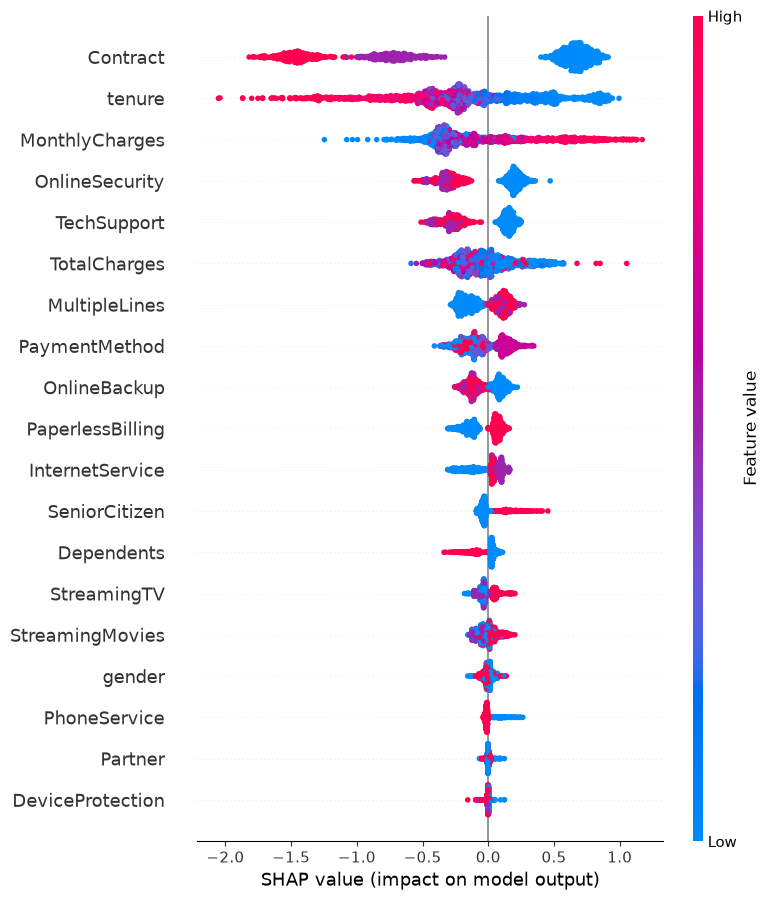

In [6]:
import shap

# 1. Initialize the SHAP TreeExplainer for your trained XGBoost model
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)

# 2. Plot the global feature importance summary
shap.summary_plot(shap_values, X_test)

In [7]:
import joblib

# Save model, scaler, and feature names
joblib.dump(model, '../models/churn_xgb_model.pkl')
joblib.dump(scaler, '../models/feature_scaler.pkl')
joblib.dump(list(X.columns), '../models/feature_names.pkl')
print('Model and preprocessing artifacts saved successfully!')

Model and preprocessing artifacts saved successfully!
